# 05 - Modèles : prédire l'Elo moyen d'une partie

**But** : entraîner des modèles sur les features du notebook 02_features et mesurer leur erreur, de la façon la plus honnête possible.

- Entrée : `Data/blitz_180_features_partie.parquet` (notebook 02_features), 1 ligne par partie, déjà découpée en train / valid / test **par joueur**
  (notebook 01_nettoyage : un joueur n'apparaît que dans un seul des trois).
- Cible : `elo_moyen` = (Elo Blancs + Elo Noirs) / 2.
- Métrique principale : la **MAE** (erreur absolue moyenne) : « en moyenne, on se trompe de X points d'Elo ».
  On suit aussi la **RMSE** (elle pénalise plus les grosses erreurs) et le **R²** (part de la variance de l'Elo expliquée, 0 = rien, 1 = parfait).

**Règles**
- Le **train** sert à apprendre, le **valid** à comparer les modèles. Le **test** n'est ouvert **qu'une seule fois**, tout à la fin (section 8),
  pour le modèle choisi. Sinon, on finit par choisir le modèle qui a eu de la chance sur le test.
- Aucune feature de fuite : pas d'Elo individuel, de `RatingDiff`, de résultat ni de `%eval` (déjà retirés par les notebooks 03 et 04).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

FEATURES_PATH = Path("../Data/blitz_180_features_partie.parquet")
CIBLE = "elo_moyen"
CATS = ["cadence", "ouv_blanc", "ouv_noir", "eco_lettre"]
IDS = ["game_id", "blanc", "noir", "split", CIBLE, "eco"]  # identifiants, cible, et eco (déjà résumé par eco_lettre)

pl.Config.set_tbl_rows(30)
plt.rcParams["figure.dpi"] = 110

## 1. Les données

In [2]:
feats = pl.read_parquet(FEATURES_PATH)
NUM = [c for c in feats.columns if c not in IDS + CATS]

train = feats.filter(pl.col("split") == "train")
valid = feats.filter(pl.col("split") == "valid")
test = feats.filter(pl.col("split") == "test")

print(feats.shape, "|", len(NUM), "features numériques +", len(CATS), "catégorielles")
feats.group_by("split").agg(parties=pl.len(), elo_moyen=pl.col(CIBLE).mean().round(), ecart_type=pl.col(CIBLE).std().round()).sort("split")

(196124, 43) | 33 features numériques + 4 catégorielles


split,parties,elo_moyen,ecart_type
str,u32,f64,f64
"""test""",8340,1688.0,345.0
"""train""",179356,1678.0,348.0
"""valid""",8428,1675.0,340.0


Les trois splits ont le même Elo moyen et la même dispersion : ils sont comparables.
Le valid et le test sont petits (~8 400 parties chacun) parce que le split se fait par joueur (explication dans le notebook 01_nettoyage, section 9).

## 2. Pourquoi pas de validation croisée par joueur ?

La validation croisée classique découpe le train en K morceaux et entraîne K fois. Ici, il faudrait que **les deux joueurs d'une partie**
soient dans le même morceau, sinon un joueur se retrouve à la fois à l'entraînement et au test (fuite : le modèle « reconnaît » son style).
On mesure si c'est possible :

In [3]:
# Chaque partie relie deux joueurs : on cherche les "groupes" de joueurs reliés entre eux (union-find).
joueurs = pl.concat([train["blanc"], train["noir"]]).unique().to_list()
indice = {j: i for i, j in enumerate(joueurs)}
parent = list(range(len(joueurs)))


def racine(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


for b, n in zip(train["blanc"].to_list(), train["noir"].to_list()):
    rb, rn = racine(indice[b]), racine(indice[n])
    if rb != rn:
        parent[rb] = rn

tailles = pl.Series([racine(i) for i in range(len(joueurs))]).value_counts().sort("count", descending=True)
print(f"{len(joueurs)} joueurs dans le train, {tailles.height} groupes ; le plus gros contient {tailles['count'][0] / len(joueurs):.0%} des joueurs")

# Si on range les joueurs en K morceaux au hasard, combien de parties ont leurs 2 joueurs dans le même morceau ?
rng = np.random.default_rng(0)
morceau = dict(zip(joueurs, rng.integers(0, 5, len(joueurs))))
meme = np.mean([morceau[b] == morceau[n] for b, n in zip(train["blanc"].to_list(), train["noir"].to_list())])
print(f"5 morceaux par joueur : seulement {meme:.0%} des parties utilisables")

86187 joueurs dans le train, 1423 groupes ; le plus gros contient 96% des joueurs


5 morceaux par joueur : seulement 20% des parties utilisables


**Décision** : presque tous les joueurs du train sont reliés entre eux par une chaîne de parties, et une validation croisée par joueur
obligerait à jeter environ 80 % des parties. On ne la fait pas.
À la place, on compare les modèles sur le **valid** (déjà séparé par joueur), et on mesure l'**incertitude** de chaque MAE par
**bootstrap** (section 5) : on retire 1 000 fois des parties du valid au hasard, avec remise, et on regarde de combien la MAE varie.

## 3. Deux références simples

Un modèle n'a d'intérêt que s'il fait mieux que des règles sans aucun apprentissage (critères de succès de `CADRAGE.md`) :
- **prédire 1500 pour tout le monde**, ce que fait Lichess pour un nouveau compte ;
- **prédire la médiane du train** pour tout le monde.

In [4]:
y_train = train[CIBLE].to_numpy()
y_valid = valid[CIBLE].to_numpy()

predictions = {
    "1500 pour tout le monde": np.full(len(y_valid), 1500.0),
    "médiane du train": np.full(len(y_valid), np.median(y_train)),
}
for nom, p in predictions.items():
    print(f"{nom:25s} MAE valid = {mean_absolute_error(y_valid, p):.1f}")

1500 pour tout le monde   MAE valid = 313.3
médiane du train          MAE valid = 271.9


## 4. Deux modèles

**Régression Ridge** : une régression linéaire (l'Elo prédit est une somme pondérée des features), avec une petite pénalité qui
empêche les poids de devenir énormes quand des features se ressemblent. Elle a besoin de features sans trous et à la même échelle :
on remplit les vides par la médiane (en gardant une colonne « était vide »), on standardise, et on transforme les catégories en colonnes 0/1.

**HistGradientBoosting** : un ensemble de petits arbres de décision, chacun corrigeant les erreurs des précédents. Il gère tout seul
les cases vides, les relations non linéaires (en cloche, en marche) et les interactions (par exemple avec la cadence).

In [5]:
pre_ridge = ColumnTransformer(
    [
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATS),
    ]
)
ridge = make_pipeline(pre_ridge, Ridge(alpha=10))
ridge.fit(train.select(NUM + CATS).to_pandas(), y_train)
predictions["Ridge"] = ridge.predict(valid.select(NUM + CATS).to_pandas())
print(f"Ridge MAE valid = {mean_absolute_error(y_valid, predictions['Ridge']):.1f}")

Ridge MAE valid = 224.7


In [6]:
# HistGradientBoosting veut des nombres : chaque catégorie devient un code (0, 1, 2...), appris sur le train.
# Une catégorie jamais vue au train devient "manquante" (NaN), ce que le modèle sait gérer.
codes = {c: {v: i for i, v in enumerate(sorted(train[c].drop_nulls().unique().to_list()))} for c in CATS}


def matrice(df):
    colonnes = [pl.col(c).replace_strict(codes[c], default=None).cast(pl.Float64) for c in CATS]
    colonnes += [pl.col(c).cast(pl.Float64) for c in NUM]
    return df.select(colonnes).to_numpy()


COLONNES = CATS + NUM
hgb = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.08, early_stopping=True, random_state=0,
    categorical_features=[c in CATS for c in COLONNES],
)
hgb.fit(matrice(train), y_train)
predictions["HistGradientBoosting"] = hgb.predict(matrice(valid))
print(f"HistGradientBoosting MAE valid = {mean_absolute_error(y_valid, predictions['HistGradientBoosting']):.1f}  ({hgb.n_iter_} arbres)")

HistGradientBoosting MAE valid = 213.5  (346 arbres)


## 5. Comparaison, avec l'incertitude

In [7]:
rng = np.random.default_rng(0)
tirages = rng.integers(0, len(y_valid), size=(1000, len(y_valid)))  # 1000 échantillons du valid, avec remise

lignes = []
for nom, p in predictions.items():
    erreurs = np.abs(y_valid - p)
    mae_boot = erreurs[tirages].mean(axis=1)
    lignes.append({
        "modèle": nom,
        "MAE": round(erreurs.mean(), 1),
        "IC 95 % bas": round(np.percentile(mae_boot, 2.5), 1),
        "IC 95 % haut": round(np.percentile(mae_boot, 97.5), 1),
        "RMSE": round(mean_squared_error(y_valid, p) ** 0.5, 1),
        "R²": round(r2_score(y_valid, p), 3),
    })
comparaison = pl.DataFrame(lignes)
comparaison

modèle,MAE,IC 95 % bas,IC 95 % haut,RMSE,R²
str,f64,f64,f64,f64,f64
"""1500 pour tout le monde""",313.3,308.7,317.9,382.1,-0.264
"""médiane du train""",271.9,267.6,276.2,340.2,-0.002
"""Ridge""",224.7,221.2,228.2,281.7,0.312
"""HistGradientBoosting""",213.5,209.9,217.1,268.5,0.375


In [8]:
# Écart entre les deux modèles, mesuré sur les MÊMES tirages (plus précis que comparer deux intervalles)
diff = (np.abs(y_valid - predictions["Ridge"]) - np.abs(y_valid - predictions["HistGradientBoosting"]))[tirages].mean(axis=1)
print(f"Ridge - HGB : {diff.mean():.1f} points de MAE, IC 95 % [{np.percentile(diff, 2.5):.1f} ; {np.percentile(diff, 97.5):.1f}]")

Ridge - HGB : 11.2 points de MAE, IC 95 % [9.6 ; 12.9]


**Lecture** : les deux modèles battent largement les deux références. L'intervalle de confiance (IC) dit entre quelles valeurs la MAE
aurait pu tomber avec un autre échantillon de parties de même taille : s'il ne se chevauche pas avec celui d'un autre modèle,
la différence n'est pas due au hasard. Le boosting fait mieux que Ridge, et l'écart entre les deux est nettement plus grand que
l'incertitude : **on choisit HistGradientBoosting.**

## 6. Où le modèle se trompe-t-il ?

In [9]:
resultats = valid.select(CIBLE).with_columns(
    prediction=pl.Series(predictions["HistGradientBoosting"]),
    tranche=(pl.col(CIBLE) // 200 * 200).clip(800, 2400),
)
par_tranche = (
    resultats.group_by("tranche")
    .agg(
        parties=pl.len(),
        MAE=(pl.col(CIBLE) - pl.col("prediction")).abs().mean().round(1),
        prediction_moyenne=pl.col("prediction").mean().round(),
    )
    .sort("tranche")
)
par_tranche

tranche,parties,MAE,prediction_moyenne
f64,u32,f64,f64
800.0,216,449.4,1354.0
1000.0,574,351.7,1454.0
1200.0,1017,251.5,1545.0
1400.0,1521,159.6,1617.0
1600.0,2004,131.3,1694.0
1800.0,1666,174.2,1761.0
2000.0,974,263.9,1830.0
2200.0,339,381.3,1903.0
2400.0,117,532.8,1970.0


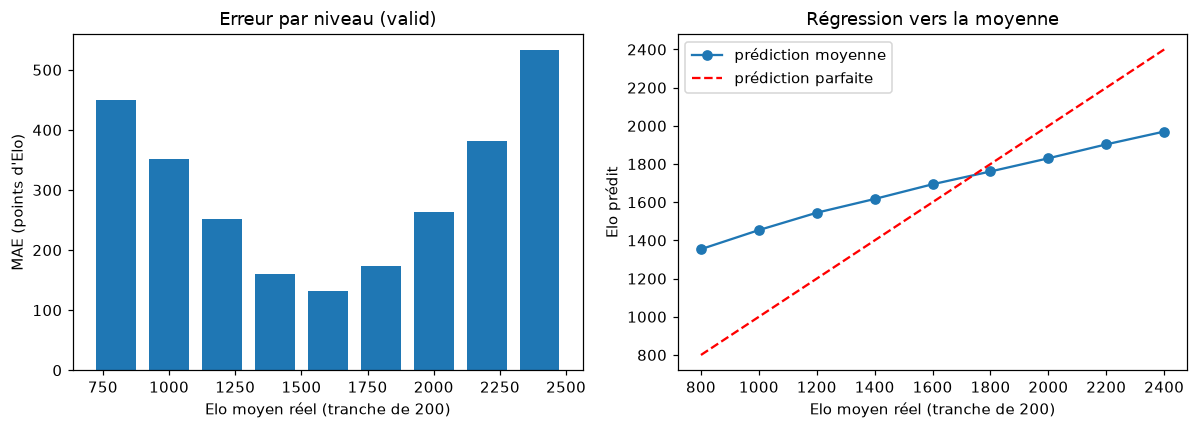

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(par_tranche["tranche"], par_tranche["MAE"], width=150)
axes[0].set_xlabel("Elo moyen réel (tranche de 200)")
axes[0].set_ylabel("MAE (points d'Elo)")
axes[0].set_title("Erreur par niveau (valid)")

axes[1].plot(par_tranche["tranche"], par_tranche["prediction_moyenne"], marker="o", label="prédiction moyenne")
axes[1].plot([800, 2400], [800, 2400], "r--", label="prédiction parfaite")
axes[1].set_xlabel("Elo moyen réel (tranche de 200)")
axes[1].set_ylabel("Elo prédit")
axes[1].set_title("Régression vers la moyenne")
axes[1].legend()

plt.tight_layout()
plt.show()

**Lecture** : l'erreur est faible au milieu (là où il y a le plus de parties) et grande aux extrêmes. Le modèle « tire » ses prédictions
vers le centre : les parties très faibles sont prédites trop fortes, les très fortes trop faibles. C'est la **régression vers la moyenne** :
quand l'information est bruitée, la prédiction la plus sûre est proche de la moyenne. Une seule partie ne suffit pas à reconnaître
un joueur très faible ou très fort avec certitude.

## 7. Quelles features comptent ?

**Importance par permutation** : on mélange au hasard une feature dans le valid et on regarde de combien la MAE augmente.
Si elle augmente beaucoup, le modèle s'appuyait sur cette feature.

In [11]:
imp = permutation_importance(hgb, matrice(valid), y_valid, scoring="neg_mean_absolute_error", n_repeats=3, random_state=0)
importances = pl.DataFrame({"feature": COLONNES, "hausse_MAE": imp.importances_mean.round(1)}).sort("hausse_MAE", descending=True)
importances.head(15)

feature,hausse_MAE
str,f64
"""pct_rapides""",15.0
"""ouv_noir""",12.2
"""cv_temps""",11.3
"""mat_abs_moy""",10.8
"""profondeur_theorie""",8.6
"""premiere_prise""",3.7
"""ouv_blanc""",3.5
"""mat_tot_20""",3.0
"""taux_gratuites""",3.0


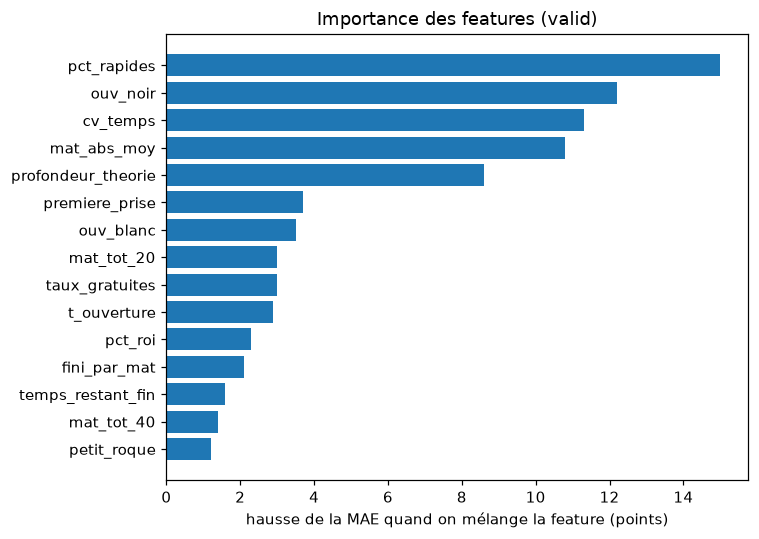

In [12]:
top = importances.head(15).reverse()
plt.figure(figsize=(7, 5))
plt.barh(top["feature"], top["hausse_MAE"])
plt.xlabel("hausse de la MAE quand on mélange la feature (points)")
plt.title("Importance des features (valid)")
plt.tight_layout()
plt.show()

## 8. Mesure finale sur le test (une seule fois)

On réentraîne le modèle choisi sur **train + valid** (plus de données, mêmes réglages), puis on le mesure **une seule fois** sur le test.
Les références sont recalculées de la même façon.

In [13]:
train_valid = pl.concat([train, valid])
y_train_valid = train_valid[CIBLE].to_numpy()
y_test = test[CIBLE].to_numpy()

codes = {c: {v: i for i, v in enumerate(sorted(train_valid[c].drop_nulls().unique().to_list()))} for c in CATS}
final = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.08, early_stopping=True, random_state=0,
    categorical_features=[c in CATS for c in COLONNES],
)
final.fit(matrice(train_valid), y_train_valid)

resultats_test = {
    "1500 pour tout le monde": np.full(len(y_test), 1500.0),
    "médiane (train + valid)": np.full(len(y_test), np.median(y_train_valid)),
    "HistGradientBoosting": final.predict(matrice(test)),
}
pl.DataFrame([
    {
        "modèle": nom,
        "MAE test": round(mean_absolute_error(y_test, p), 1),
        "RMSE test": round(mean_squared_error(y_test, p) ** 0.5, 1),
        "R² test": round(r2_score(y_test, p), 3),
    }
    for nom, p in resultats_test.items()
])

modèle,MAE test,RMSE test,R² test
str,f64,f64,f64
"""1500 pour tout le monde""",322.4,393.1,-0.298
"""médiane (train + valid)""",276.6,345.1,-0.0
"""HistGradientBoosting""",212.2,266.5,0.403


## Bilan

Chiffres de cette exécution :

| modèle | MAE valid (IC 95 %) | MAE test | R² test |
|---|---|---|---|
| 1500 pour tout le monde | 313,3 | 322,4 | -0,30 |
| médiane | 271,9 | 276,6 | 0,00 |
| Ridge | 224,7 (221,2 - 228,2) | | |
| HistGradientBoosting | 213,5 (209,9 - 217,1) | **212,2** | **0,40** |

- Les deux modèles battent nettement les deux références. Le boosting fait ~11 points de mieux que Ridge (IC 95 % : 9,6 à 12,9) :
  la différence n'est pas due au hasard. Sur le test, il gagne **64 points** par rapport à la médiane et **110 points** par rapport à « 1500 ».
- La MAE du test (212,2) est très proche de celle du valid (213,5) : le modèle n'a pas été « sur-ajusté » au valid.
- L'erreur dépend beaucoup du niveau : ~130 points vers 1600, mais ~450 vers 800 et ~530 vers 2400 (régression vers la moyenne).
- Les features les plus utiles : la part de coups rapides, la réponse des Noirs à l'ouverture, la régularité du temps de réflexion (`cv_temps`),
  le déséquilibre de matériel moyen et la profondeur de théorie.

**Limites**
- Une seule journée de blitz 3 min (Lichess, 1er septembre 2026), et une population filtrée (pas de comptes provisoires,
  peu de tournois) : le modèle est moins fiable en dehors.
- Pas de validation croisée par joueur (section 2) : l'incertitude est mesurée par bootstrap sur un valid de ~8 400 parties.
- Réglages du boosting fixés à la main, sans recherche systématique.